# Experiment 06 — Final Frozen Evaluation

## Purpose and evaluation discipline

Development model selection is complete. Histogram gradient boosting is frozen
as the final model based only on the five development subject folds.

The selected development result is:

**mean macro-F1: 0.7446 ± 0.0432**

The frozen pipeline uses:

- paired watch accelerometer and gyroscope sequences;
- 100 samples over each five-second window at 20 Hz;
- the fixed 222 statistical, temporal, and frequency features;
- histogram gradient boosting with the configuration recorded in
  `modeling/artifacts/final_model_spec.json`;
- all 25,585 examples from the 41 development subjects for the final fit.

This notebook performs one reserved-test evaluation. No model, feature,
preprocessing, or hyperparameter decisions may be changed in response to its
result.

Before loading any test artifact, the shared feature extractor must reproduce
the previously saved development feature table exactly.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd


CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [
            CURRENT_DIR,
            *CURRENT_DIR.parents,
        ]
        if (
            candidate
            / "modeling"
            / "artifacts"
            / "final_model_spec.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the activity_project root."
    )

MODELING_DIR = (
    PROJECT_ROOT
    / "modeling"
)

if str(MODELING_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(MODELING_DIR),
    )

from engineered_features import (
    extract_engineered_features,
)


SEQUENCE_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "modified"
    / "watch_pair_20hz"
)

MODEL_ARTIFACT_DIR = (
    MODELING_DIR
    / "artifacts"
)

TRAIN_SEQUENCE_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "train_sequences.npz"
)

TRAIN_METADATA_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "train_metadata.parquet"
)

TRAIN_FEATURE_PATH = (
    MODEL_ARTIFACT_DIR
    / "engineered_222_train.parquet"
)

FEATURE_META_PATH = (
    MODEL_ARTIFACT_DIR
    / "engineered_222_meta.json"
)

FINAL_SPEC_PATH = (
    MODEL_ARTIFACT_DIR
    / "final_model_spec.json"
)

PREPROCESSING_META_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "preprocessing_meta.json"
)

feature_meta = json.loads(
    FEATURE_META_PATH.read_text(
        encoding="utf-8"
    )
)

final_model_spec = json.loads(
    FINAL_SPEC_PATH.read_text(
        encoding="utf-8"
    )
)

preprocessing_meta = json.loads(
    PREPROCESSING_META_PATH.read_text(
        encoding="utf-8"
    )
)

assert final_model_spec["status"] == (
    "frozen_before_reserved_test_access"
)

feature_names = feature_meta[
    "feature_names"
]

target_rate_hz = float(
    preprocessing_meta[
        "resampling"
    ]["target_rate_hz"]
)

with np.load(
    TRAIN_SEQUENCE_PATH
) as artifact:
    recomputed_train_features, (
        recomputed_feature_names
    ) = extract_engineered_features(
        artifact["accel"],
        artifact["gyro"],
        target_rate_hz,
    )

train_feature_table = pd.read_parquet(
    TRAIN_FEATURE_PATH
)

train_metadata = pd.read_parquet(
    TRAIN_METADATA_PATH
)

assert recomputed_feature_names == (
    feature_names
)

assert train_feature_table.columns.tolist() == [
    "array_index",
    *feature_names,
]

assert np.array_equal(
    train_feature_table[
        "array_index"
    ].to_numpy(),
    train_metadata[
        "array_index"
    ].to_numpy(),
)

X_train = (
    train_feature_table[
        feature_names
    ].to_numpy()
)

assert np.array_equal(
    recomputed_train_features,
    X_train,
)

assert np.isfinite(
    X_train
).all()

ACTIVITY_CODES = preprocessing_meta[
    "labels"
]["activity_codes_in_order"]

y_train = (
    train_metadata[
        "activity_code"
    ]
    .astype(str)
    .to_numpy()
)

assert X_train.shape == (
    25_585,
    222,
)
assert len(
    np.unique(
        train_metadata[
            "user_id"
        ]
    )
) == 41
assert set(y_train) == set(
    ACTIVITY_CODES
)

del recomputed_train_features

print(
    "Frozen specification:",
    final_model_spec[
        "status"
    ],
)
print(
    "Training feature shape:",
    X_train.shape,
)
print(
    "Feature names match:",
    True,
)
print(
    "Exact training-value parity:",
    True,
)
print(
    "Reserved test artifacts "
    "have not been loaded."
)

Frozen specification: frozen_before_reserved_test_access
Training feature shape: (25585, 222)
Feature names match: True
Exact training-value parity: True
Reserved test artifacts have not been loaded.


## 1. Load the reserved test artifact

The development feature implementation has passed exact parity and the final
model specification is frozen. The reserved test artifact may now be loaded.

The same deterministic extractor is applied without fitting or modifying any
transformation. This subsection verifies only structural alignment, expected
subjects, feature order, shape, and finiteness. It does not yet fit the final
model or calculate test performance.

In [4]:
TEST_SEQUENCE_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "test_sequences.npz"
)

TEST_METADATA_PATH = (
    SEQUENCE_ARTIFACT_DIR
    / "test_metadata.parquet"
)

test_metadata = pd.read_parquet(
    TEST_METADATA_PATH
)

with np.load(
    TEST_SEQUENCE_PATH
) as artifact:
    X_test, test_feature_names = (
        extract_engineered_features(
            artifact["accel"],
            artifact["gyro"],
            target_rate_hz,
        )
    )

assert test_feature_names == (
    feature_names
)

assert np.array_equal(
    test_metadata[
        "array_index"
    ].to_numpy(),
    np.arange(
        len(test_metadata)
    ),
)

expected_test_subjects = set(
    preprocessing_meta[
        "subjects"
    ]["test"]
)

observed_test_subjects = set(
    test_metadata[
        "user_id"
    ]
    .astype(int)
    .unique()
)

development_subjects = set(
    train_metadata[
        "user_id"
    ]
    .astype(int)
    .unique()
)

assert observed_test_subjects == (
    expected_test_subjects
)

assert development_subjects.isdisjoint(
    observed_test_subjects
)

assert X_test.shape == (
    final_model_spec[
        "final_fit"
    ][
        "reserved_test_examples"
    ],
    final_model_spec[
        "features"
    ]["count"],
)

assert np.isfinite(
    X_test
).all()

y_test = (
    test_metadata[
        "activity_code"
    ]
    .astype(str)
    .to_numpy()
)

assert set(y_test).issubset(
    set(ACTIVITY_CODES)
)

print(
    "Reserved test examples:",
    f"{len(test_metadata):,}",
)
print(
    "Test feature shape:",
    X_test.shape,
)
print(
    "Reserved test subjects:",
    len(
        observed_test_subjects
    ),
)
print(
    "Feature contract matches:",
    True,
)
print(
    "Development/test subjects disjoint:",
    True,
)
print(
    "No predictions have been computed."
)

Reserved test examples: 6,161
Test feature shape: (6161, 222)
Reserved test subjects: 10
Feature contract matches: True
Development/test subjects disjoint: True
No predictions have been computed.


## 2. Fit the frozen model and evaluate once

The structural test checks passed without altering the frozen pipeline. The
histogram-gradient-boosting parameters are now read directly from the frozen
specification.

The model is fitted once on every development example and used to generate one
prediction for every reserved-test example. The fitted estimator and prediction
table are persisted immediately. All subsequent diagnostics will use these
stored predictions rather than refitting or predicting again.

This is the final test evaluation. Its outcome will be reported as observed and
will not trigger changes to the selected pipeline.

In [5]:
from time import perf_counter

import joblib
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
)


estimator_parameters = (
    final_model_spec[
        "estimator"
    ]["parameters"].copy()
)

expected_parameters = {
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
    "early_stopping": False,
    "class_weight": None,
    "random_state": 42,
}

assert estimator_parameters == (
    expected_parameters
)

final_model = (
    HistGradientBoostingClassifier(
        **estimator_parameters
    )
)

fit_start = perf_counter()

final_model.fit(
    X_train,
    y_train,
)

fit_seconds = (
    perf_counter()
    - fit_start
)

prediction_start = perf_counter()

final_test_y_pred = (
    final_model.predict(
        X_test
    )
)

prediction_seconds = (
    perf_counter()
    - prediction_start
)

assert len(
    final_test_y_pred
) == len(test_metadata)

assert set(
    final_test_y_pred
).issubset(
    set(ACTIVITY_CODES)
)

final_test_predictions = (
    test_metadata[
        [
            "array_index",
            "pair_id",
            "user_id",
            "activity_code",
        ]
    ]
    .rename(
        columns={
            "activity_code": (
                "y_true"
            ),
        }
    )
    .copy()
)

final_test_predictions[
    "y_pred"
] = final_test_y_pred

assert final_test_predictions[
    "array_index"
].is_unique

final_test_metrics = {
    "accuracy": accuracy_score(
        y_test,
        final_test_y_pred,
    ),
    "balanced_accuracy": recall_score(
        y_test,
        final_test_y_pred,
        labels=ACTIVITY_CODES,
        average="macro",
        zero_division=0,
    ),
    "macro_f1": f1_score(
        y_test,
        final_test_y_pred,
        labels=ACTIVITY_CODES,
        average="macro",
        zero_division=0,
    ),
}

FINAL_MODEL_PATH = (
    MODEL_ARTIFACT_DIR
    / "final_hgb_model.joblib"
)

FINAL_PREDICTIONS_PATH = (
    MODEL_ARTIFACT_DIR
    / "final_test_predictions.parquet"
)

joblib.dump(
    final_model,
    FINAL_MODEL_PATH,
)

final_test_predictions.to_parquet(
    FINAL_PREDICTIONS_PATH,
    index=False,
)

print(
    "FINAL RESERVED-TEST EVALUATION"
)
print(
    "Training examples:",
    f"{len(y_train):,}",
)
print(
    "Test examples:",
    f"{len(y_test):,}",
)
print(
    "Accuracy:",
    f"{final_test_metrics['accuracy']:.4f}",
)
print(
    "Balanced accuracy:",
    (
        f"{final_test_metrics['balanced_accuracy']:.4f}"
    ),
)
print(
    "Macro-F1:",
    f"{final_test_metrics['macro_f1']:.4f}",
)
print(
    "Fit time:",
    f"{fit_seconds:.1f}s",
)
print(
    "Prediction time:",
    f"{prediction_seconds:.1f}s",
)
print(
    "Saved model:",
    FINAL_MODEL_PATH,
)
print(
    "Saved predictions:",
    FINAL_PREDICTIONS_PATH,
)

FINAL RESERVED-TEST EVALUATION
Training examples: 25,585
Test examples: 6,161
Accuracy: 0.6780
Balanced accuracy: 0.6773
Macro-F1: 0.6851
Fit time: 57.1s
Prediction time: 0.5s
Saved model: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project/modeling/artifacts/final_hgb_model.joblib
Saved predictions: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project/modeling/artifacts/final_test_predictions.parquet


### Aggregate final result

The frozen model achieves reserved-test accuracy **0.6780**, balanced accuracy
**0.6773**, and macro-F1 **0.6851**.

Test macro-F1 is 0.0595 below the development-fold mean of 0.7446 and slightly
below the lowest individual development-fold result of 0.6895. This indicates
that the ten reserved subjects form a more difficult generalization population
than the average development fold.

The difference does not alter the selected pipeline. The model, features, and
hyperparameters were frozen before test access, and this result is reported as
the final unbiased evaluation for the current development cycle.

The fitted model and one-time test predictions have been persisted. All
remaining analysis uses the stored prediction table and does not refit the
model or generate new predictions.

## 3. Per-activity performance and confusion structure

Aggregate macro-F1 weights every activity equally but does not show which
activities generalize successfully to the reserved subjects. We therefore
report precision, recall, F1, and support for each activity.

A row-normalized confusion matrix shows how each true activity's examples are
distributed across predicted classes. The largest incorrect destination for
each activity is also tabulated to make the main confusion patterns explicit.

,activity_code,activity_name,precision,recall,f1,support
0,L,Eating Sandwich,0.146,0.219,0.175,315
1,I,Eating Chips,0.447,0.349,0.392,350
2,D,Sitting,0.373,0.631,0.469,350
3,J,Eating Pasta,0.534,0.449,0.488,350
4,K,Drinking from Cup,0.582,0.469,0.519,350
5,H,Eating Soup,0.616,0.463,0.529,350
6,E,Standing,0.545,0.924,0.686,315
7,R,Clapping,0.892,0.660,0.759,350
8,S,Folding Clothes,0.716,0.837,0.772,350
9,F,Typing,0.918,0.674,0.778,350


,true_activity,most_confused_with,confusion_count,fraction_of_true_activity
0,Eating Sandwich,Eating Chips,84,0.267
1,Eating Chips,Eating Sandwich,87,0.249
2,Eating Soup,Eating Sandwich,73,0.209
3,Eating Pasta,Eating Soup,66,0.189
4,Drinking from Cup,Eating Sandwich,65,0.186
5,Clapping,Sitting,49,0.140
6,Typing,Sitting,46,0.131
7,Folding Clothes,Standing,45,0.129
8,Brushing Teeth,Eating Sandwich,40,0.114
9,Sitting,Drinking from Cup,40,0.114


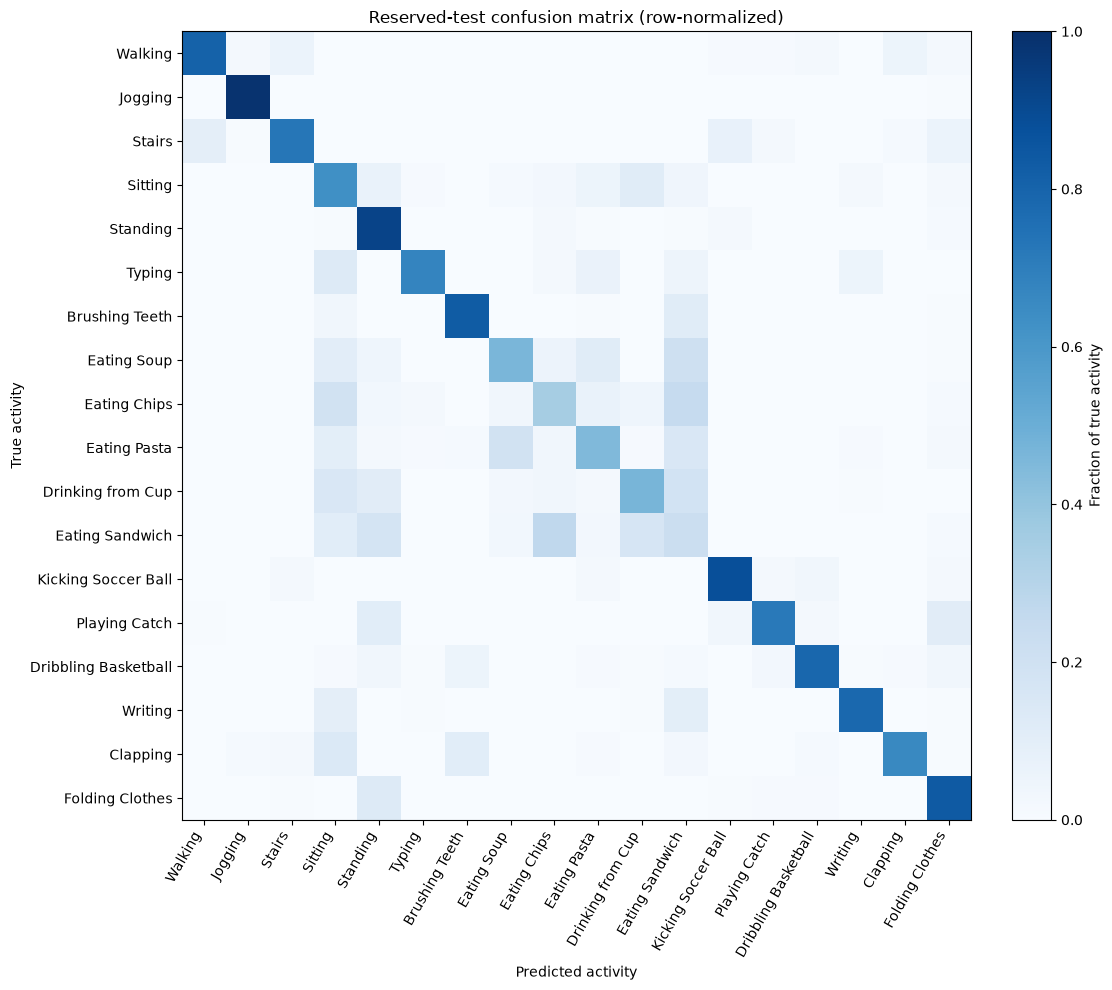

In [6]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support,
)


stored_test_predictions = (
    pd.read_parquet(
        FINAL_PREDICTIONS_PATH
    )
)

assert len(
    stored_test_predictions
) == len(test_metadata)

assert np.array_equal(
    stored_test_predictions[
        "array_index"
    ].to_numpy(),
    test_metadata[
        "array_index"
    ].to_numpy(),
)

ACTIVITY_MAP = {
    "A": "Walking",
    "B": "Jogging",
    "C": "Stairs",
    "D": "Sitting",
    "E": "Standing",
    "F": "Typing",
    "G": "Brushing Teeth",
    "H": "Eating Soup",
    "I": "Eating Chips",
    "J": "Eating Pasta",
    "K": "Drinking from Cup",
    "L": "Eating Sandwich",
    "M": "Kicking Soccer Ball",
    "O": "Playing Catch",
    "P": "Dribbling Basketball",
    "Q": "Writing",
    "R": "Clapping",
    "S": "Folding Clothes",
}

(
    activity_precision,
    activity_recall,
    activity_f1,
    activity_support,
) = precision_recall_fscore_support(
    stored_test_predictions[
        "y_true"
    ],
    stored_test_predictions[
        "y_pred"
    ],
    labels=ACTIVITY_CODES,
    zero_division=0,
)

activity_test_metrics = pd.DataFrame({
    "activity_code": (
        ACTIVITY_CODES
    ),
    "activity_name": [
        ACTIVITY_MAP[
            activity_code
        ]
        for activity_code
        in ACTIVITY_CODES
    ],
    "precision": (
        activity_precision
    ),
    "recall": activity_recall,
    "f1": activity_f1,
    "support": (
        activity_support
        .astype(int)
    ),
})

raw_confusion = confusion_matrix(
    stored_test_predictions[
        "y_true"
    ],
    stored_test_predictions[
        "y_pred"
    ],
    labels=ACTIVITY_CODES,
)

normalized_confusion = np.divide(
    raw_confusion,
    raw_confusion.sum(
        axis=1,
        keepdims=True,
    ),
    out=np.zeros_like(
        raw_confusion,
        dtype=float,
    ),
    where=(
        raw_confusion.sum(
            axis=1,
            keepdims=True,
        )
        > 0
    ),
)

confusion_rows = []

for activity_index, activity_code in enumerate(
    ACTIVITY_CODES
):
    incorrect_counts = (
        raw_confusion[
            activity_index
        ].copy()
    )

    incorrect_counts[
        activity_index
    ] = 0

    confused_index = int(
        incorrect_counts.argmax()
    )

    confusion_count = int(
        incorrect_counts[
            confused_index
        ]
    )

    confusion_rows.append({
        "true_activity": (
            ACTIVITY_MAP[
                activity_code
            ]
        ),
        "most_confused_with": (
            ACTIVITY_MAP[
                ACTIVITY_CODES[
                    confused_index
                ]
            ]
        ),
        "confusion_count": (
            confusion_count
        ),
        "fraction_of_true_activity": (
            confusion_count
            / raw_confusion[
                activity_index
            ].sum()
        ),
    })

largest_activity_confusions = (
    pd.DataFrame(
        confusion_rows
    )
    .sort_values(
        "fraction_of_true_activity",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    activity_test_metrics
    .sort_values(
        "f1"
    )
    .reset_index(drop=True)
    .round(3)
)

display(
    largest_activity_confusions
    .round(3)
)

activity_names = [
    ACTIVITY_MAP[
        activity_code
    ]
    for activity_code
    in ACTIVITY_CODES
]

figure, axis = plt.subplots(
    figsize=(12, 10)
)

image = axis.imshow(
    normalized_confusion,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

axis.set_xticks(
    np.arange(
        len(activity_names)
    ),
    labels=activity_names,
    rotation=60,
    ha="right",
)

axis.set_yticks(
    np.arange(
        len(activity_names)
    ),
    labels=activity_names,
)

axis.set_xlabel(
    "Predicted activity"
)
axis.set_ylabel(
    "True activity"
)
axis.set_title(
    "Reserved-test confusion matrix "
    "(row-normalized)"
)

colorbar = figure.colorbar(
    image,
    ax=axis,
    fraction=0.046,
    pad=0.04,
)

colorbar.set_label(
    "Fraction of true activity"
)

figure.tight_layout()
plt.show()

### Activity-level interpretation

Reserved-test performance varies substantially by activity. Jogging is the
strongest class at F1 0.973, followed by Kicking Soccer Ball, Walking, Writing,
Dribbling Basketball, and Brushing Teeth. These activities retain relatively
distinct watch-motion patterns for the reserved subjects.

The largest weakness is Eating Sandwich, with F1 0.175. The dominant error
structure is a cluster of similar eating and hand-to-mouth activities:
Eating Sandwich, Eating Chips, Eating Soup, Eating Pasta, and Drinking from Cup
are frequently confused with one another. Eating Sandwich acts as both a weak
class and a common incorrect destination.

Sitting also has low F1 despite recall of 0.631 because its precision is only
0.373. Some Clapping and Typing examples are predicted as Sitting. Additional
posture-related errors include Folding Clothes being predicted as Standing.

The final performance gap is therefore not uniform across the 18 activities.
Large and periodic motions generalize comparatively well, while subtle
hand-oriented activities with similar watch movement remain the main
limitation.

## 4. Subject-level performance distribution

The final aggregate metrics combine ten previously unseen subjects. To
determine whether the test result reflects a broad decrease or a few especially
difficult people, accuracy, balanced accuracy, and macro-F1 are calculated
separately for each subject.

Subject macro-F1 includes only activities actually represented for that
subject. This matters because one known subject/activity combination is absent
from the reserved population.

,user_id,examples,activities_present,accuracy,balanced_accuracy,macro_f1
0,1640,560,16,0.1857,0.1857,0.2059
1,1639,595,17,0.3529,0.3529,0.3371
2,1607,631,18,0.6038,0.6035,0.5746
3,1629,630,18,0.7063,0.7063,0.6718
4,1646,630,18,0.7587,0.7587,0.7531
5,1618,595,17,0.7782,0.7782,0.7786
6,1626,630,18,0.8190,0.8190,0.8089
7,1641,630,18,0.8063,0.8063,0.8124
8,1606,630,18,0.8270,0.8270,0.8204
9,1643,630,18,0.8746,0.8746,0.8706


,accuracy,balanced_accuracy,macro_f1
mean,0.6713,0.6712,0.6633
std,0.2279,0.2280,0.2251
min,0.1857,0.1857,0.2059
median,0.7684,0.7684,0.7658
max,0.8746,0.8746,0.8706


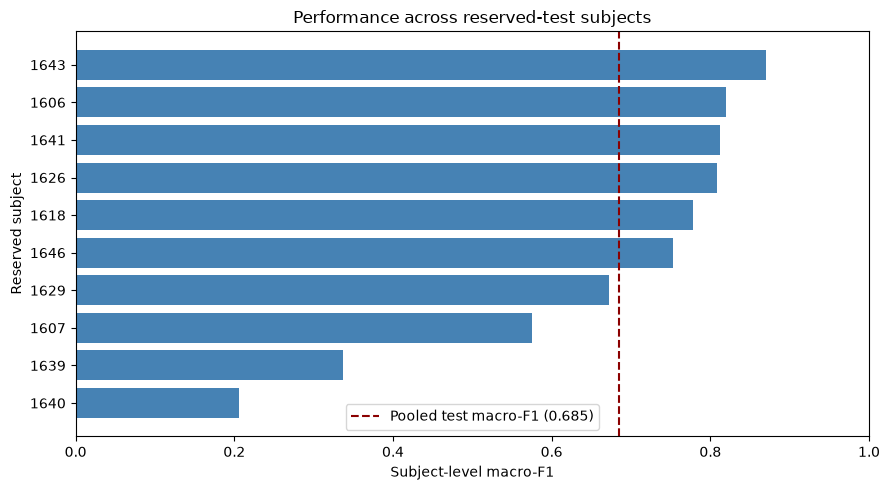

In [7]:
subject_rows = []

for user_id, subject_predictions in (
    stored_test_predictions.groupby(
        "user_id",
        sort=True,
    )
):
    labels_present = [
        activity_code
        for activity_code
        in ACTIVITY_CODES
        if activity_code
        in set(
            subject_predictions[
                "y_true"
            ]
        )
    ]

    subject_rows.append({
        "user_id": int(
            user_id
        ),
        "examples": len(
            subject_predictions
        ),
        "activities_present": len(
            labels_present
        ),
        "accuracy": accuracy_score(
            subject_predictions[
                "y_true"
            ],
            subject_predictions[
                "y_pred"
            ],
        ),
        "balanced_accuracy": recall_score(
            subject_predictions[
                "y_true"
            ],
            subject_predictions[
                "y_pred"
            ],
            labels=labels_present,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            subject_predictions[
                "y_true"
            ],
            subject_predictions[
                "y_pred"
            ],
            labels=labels_present,
            average="macro",
            zero_division=0,
        ),
    })

subject_test_metrics = (
    pd.DataFrame(
        subject_rows
    )
    .sort_values(
        "macro_f1"
    )
    .reset_index(drop=True)
)

subject_metric_summary = (
    subject_test_metrics[
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
        ]
    ]
    .agg([
        "mean",
        "std",
        "min",
        "median",
        "max",
    ])
)

display(
    subject_test_metrics.round(4)
)

display(
    subject_metric_summary.round(4)
)

figure, axis = plt.subplots(
    figsize=(9, 5)
)

axis.barh(
    subject_test_metrics[
        "user_id"
    ].astype(str),
    subject_test_metrics[
        "macro_f1"
    ],
    color="steelblue",
)

axis.axvline(
    final_test_metrics[
        "macro_f1"
    ],
    color="darkred",
    linestyle="--",
    label=(
        "Pooled test macro-F1 "
        f"({final_test_metrics['macro_f1']:.3f})"
    ),
)

axis.set_xlim(0, 1)
axis.set_xlabel(
    "Subject-level macro-F1"
)
axis.set_ylabel(
    "Reserved subject"
)
axis.set_title(
    "Performance across reserved-test subjects"
)
axis.legend()
figure.tight_layout()
plt.show()

## 5. Final findings

The complete frozen pipeline was fitted on 25,585 paired-watch examples from
all 41 development subjects and evaluated once on 6,161 examples from the ten
reserved subjects.

### Final performance

| Metric | Reserved test |
|---|---:|
| Accuracy | **0.6780** |
| Balanced accuracy | **0.6773** |
| Macro-F1 | **0.6851** |

The final macro-F1 is 0.0595 below the five-fold development mean of 0.7446
and slightly below the weakest individual development fold. The reserved
subjects therefore form a more difficult generalization population than the
average development fold.

### Activity behavior

Performance is strongest for distinctive locomotion and larger-motion
activities. Jogging reaches F1 0.973, while Kicking Soccer Ball, Walking,
Writing, Dribbling Basketball, and Brushing Teeth all exceed 0.82.

The principal weakness is the group of similar hand-to-mouth activities.
Eating Sandwich reaches only F1 0.175 and is frequently confused with Eating
Chips. Eating Chips, Eating Soup, Eating Pasta, and Drinking from Cup also show
substantial mutual confusion. Sitting has low precision because some Clapping
and Typing examples are predicted as Sitting.

These errors show that the aggregate decline is not uniform across activities.
The watch-based engineered representation generalizes well for distinctive
motion but has difficulty separating subtle activities with similar wrist
movement.

### Subject behavior

Generalization also varies sharply between reserved subjects. Subject-level
macro-F1 ranges from 0.2059 to 0.8706, with a median of 0.7658 and standard
deviation of 0.2251.

Six of ten subjects exceed macro-F1 0.75. In contrast, subjects 1639 and 1640
reach only 0.3371 and 0.2059. These two difficult subjects strongly affect the
aggregate result, while most reserved subjects perform much closer to—or above—
the development expectation.

This subject heterogeneity is an important practical finding: strong average
development performance does not guarantee reliable performance for every new
wearer.

### Final decision

Histogram gradient boosting remains the final model for this completed
development cycle. Its pipeline consists of:

- paired watch accelerometer and gyroscope sequences resampled to 20 Hz;
- the fixed 222 statistical, distributional, temporal, and frequency features;
- 200 histogram-gradient-boosting iterations with the configuration frozen
  before test access.

The lower reserved-test result does not trigger model or preprocessing changes.
The fitted model and original test predictions are retained as the final
artifacts, and the test set will not be reused for further model selection.